# 02 - Model Experiments: Fully Connected DNN Architectures

**Project:** DNN-Image-Classifier (fully connected network, no CNNs)

The baseline model reaches about 89.5% test accuracy. This notebook asks a practical question: **can a different depth, width, dropout rate, or learning rate do better, and how sure are we?**

## Experimental design

Searching every combination (7 architectures x 6 dropout rates x 5 learning rates = 210 runs) is too expensive, so we use a **greedy, one-factor-at-a-time search**: tune one factor, fix its best value, and move on to the next.

| Phase | Question | What varies | What is fixed |
|---|---|---|---|
| 0 | Where do we start? | Project default model | - |
| 1 | How do depth and width matter? | 7 architectures | dropout 0.3, learning rate 1e-3 |
| 2 | How much dropout is right? | dropout 0.0 to 0.5 | best architecture of phase 1 |
| 3 | Which learning rate is best? | 1e-2 to 1e-4 | best architecture + dropout |
| 4 | Is the winner real or just luck? | 3 random seeds | top-3 configs + the reference |

## Ground rules

1. **Same data for every run.** Loading, flattening, normalization and the 85/15 stratified split come from `src.data_loader`, and the model is built with `src.model.build_model`, so these experiments use the exact code of the project.
2. **EarlyStopping in every run** (monitor `val_loss`, best weights restored). No learning-rate scheduler is used, so the learning-rate experiment is not mixed up with a schedule.
3. **Models are selected on validation data only.** Test accuracy is recorded for every run (for transparency), but it is *never* used to pick a model. Choosing by test accuracy would leak the test set into the selection and make the final number optimistic.
4. **Single runs are noisy.** Differences of a few hundredths of a percent can come from random initialization alone, so Phase 4 repeats the best candidates with several seeds before we decide.

> **Runtime:** about 30 to 60 minutes on an Apple Silicon Mac. To check quickly that everything runs, set `QUICK_MODE = True` in the configuration cell (3 epochs per run).

## 1. Setup

In [1]:
import gc
import json
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator
from tensorflow import keras

# Make `src` importable whether the notebook runs from notebooks/ or the project root
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data
from src.model import build_model

REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"TensorFlow   : {tf.__version__}")
print(f"Project root : {PROJECT_ROOT}")

TensorFlow   : 2.15.0
Project root : /Users/mohamedashraf/Projects/DNN-Image-Classifier


### Configuration

All experiment settings live in one place.

In [2]:
QUICK_MODE = False          # True = smoke test (3 epochs, 1 seed) to check the notebook end to end

SEED = 42                   # main seed (also used for the data split)
SEEDS = (SEED,) if QUICK_MODE else (42, 43, 44)   # seeds for the robustness check (phase 4)

BATCH_SIZE = 256
MAX_EPOCHS = 3 if QUICK_MODE else 60
ES_PATIENCE = 8             # EarlyStopping patience on val_loss

BASE_LR = 1e-3
BASE_DROPOUT = 0.3
TIE_MARGIN = 0.0005         # validation accuracies closer than 0.05 points count as a tie

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight"})
PALETTE = sns.color_palette("deep")

### Data

The data is loaded once and shared by all experiments. The validation split is stratified (900 images per class) and fixed, so every model is compared on exactly the same validation images.

In [3]:
X_train, y_train, X_val, y_val, X_test, y_test = load_data(
    val_split=0.15, one_hot=False, seed=SEED
)
print(f"train: {X_train.shape}   val: {X_val.shape}   test: {X_test.shape}")
print(f"pixel range: [{X_train.min():.1f}, {X_train.max():.1f}]   labels: integers 0-9")

train: (51000, 784)   val: (9000, 784)   test: (10000, 784)
pixel range: [0.0, 1.0]   labels: integers 0-9


## 2. Experiment Infrastructure

`run_experiment` trains one configuration and returns a record with all metrics. Two details make the comparison fair:

- **Fresh state per run:** the Keras session is cleared and the seed is set before every run.
- **Best weights are always restored.** In some Keras versions `EarlyStopping(restore_best_weights=True)` only restores the weights when it actually stops the training. A small helper callback restores the best epoch in every case, so the reported metrics always belong to the best epoch.

Results are cached by configuration, so a configuration that appears in two phases is trained only once.

In [4]:
class RestoreBestWeights(keras.callbacks.Callback):
    # Restore the weights of the epoch with the lowest val_loss when training ends.

    def __init__(self):
        super().__init__()
        self.best_loss = np.inf
        self.best_weights = None
        self.best_epoch = 0

    def on_epoch_end(self, epoch, logs=None):
        if logs["val_loss"] < self.best_loss:
            self.best_loss = logs["val_loss"]
            self.best_weights = self.model.get_weights()
            self.best_epoch = epoch + 1

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)


def set_global_seed(seed):
    # Seed Python, NumPy and TensorFlow so a run is reproducible.
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


RESULTS = []      # one record per trained model
HISTORIES = {}    # run id -> Keras history (for the curves)
_CACHE = {}       # config key -> record


def uniform_dropout(hidden_units, rate):
    return (rate,) * len(hidden_units)


def dropout_label(rates):
    if len(set(rates)) == 1:
        return f"{rates[0]:g}"
    return "-".join(f"{r:g}" for r in rates)


def config_label(hidden_units, rates, lr):
    layers = "-".join(map(str, hidden_units))
    return f"{layers} | dropout {dropout_label(rates)} | lr {lr:g}"


def run_experiment(name, hidden_units, dropout_rates, learning_rate=BASE_LR, seed=SEED, phase=""):
    # Train one configuration and return its metrics as a dict.
    hidden_units, dropout_rates = tuple(hidden_units), tuple(dropout_rates)
    key = (hidden_units, dropout_rates, float(learning_rate), seed)
    if key in _CACHE:
        print(f"[cached] {name}")
        return _CACHE[key]

    keras.backend.clear_session()
    gc.collect()          # free the previous model before building the next one
    set_global_seed(seed)

    model = build_model(
        input_shape=(X_train.shape[1],),
        hidden_units=hidden_units,
        dropout_rates=dropout_rates,
        learning_rate=learning_rate,
    )
    restore = RestoreBestWeights()
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=ES_PATIENCE, restore_best_weights=True
        ),
        restore,
    ]

    start = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        shuffle=True,
        verbose=0,
    )
    train_time = time.perf_counter() - start

    # Evaluate the restored (best-epoch) model. Train accuracy is measured with
    # dropout switched off, so it is directly comparable with val/test accuracy.
    train_loss, train_acc = model.evaluate(X_train, y_train, batch_size=1024, verbose=0)
    val_loss, val_acc = model.evaluate(X_val, y_val, batch_size=1024, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, batch_size=1024, verbose=0)

    record = {
        "id": len(RESULTS) + 1,
        "phase": phase,
        "name": name,
        "layers": "-".join(map(str, hidden_units)),
        "depth": len(hidden_units),
        "dropout": dropout_label(dropout_rates),
        "dropout_mean": float(np.mean(dropout_rates)),
        "learning_rate": float(learning_rate),
        "seed": seed,
        "params": int(model.count_params()),
        "epochs_run": len(history.history["loss"]),
        "best_epoch": restore.best_epoch,
        "train_time_s": train_time,
        "train_acc": float(train_acc),
        "val_acc": float(val_acc),
        "test_acc": float(test_acc),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "test_loss": float(test_loss),
        "gap": float(train_acc - val_acc),
        "config_label": config_label(hidden_units, dropout_rates, learning_rate),
        "config": {
            "hidden_units": hidden_units,
            "dropout_rates": dropout_rates,
            "learning_rate": float(learning_rate),
        },
    }

    _CACHE[key] = record
    RESULTS.append(record)
    HISTORIES[record["id"]] = history.history

    print(
        f"[{record['id']:02d}] {name:<46} params={record['params']:>9,} "
        f"epochs={record['epochs_run']:>2} val={val_acc:.4f} test={test_acc:.4f} "
        f"time={train_time:5.1f}s"
    )
    del model, history, restore, callbacks
    keras.backend.clear_session()
    gc.collect()
    return record


def pick_best(records):
    # Best run by validation accuracy (ties broken by lower validation loss).
    return max(records, key=lambda r: (r["val_acc"], -r["val_loss"]))


TABLE_COLUMNS = [
    "name", "layers", "dropout", "learning_rate", "params", "epochs_run",
    "best_epoch", "train_time_s", "train_acc", "val_acc", "test_acc", "gap",
]
TABLE_FORMAT = {
    "learning_rate": "{:g}", "params": "{:,}", "train_time_s": "{:.0f}",
    "train_acc": "{:.4f}", "val_acc": "{:.4f}", "test_acc": "{:.4f}", "gap": "{:+.4f}",
}


def show_table(records, columns=TABLE_COLUMNS):
    # Display records as a formatted table, best validation accuracy highlighted.
    df = pd.DataFrame(records)[columns]
    display(
        df.style.format(TABLE_FORMAT)
        .highlight_max(subset=["val_acc"], color="#c6efce")
        .hide(axis="index")
    )


def save_figure(fig, filename):
    path = FIGURES_DIR / filename
    fig.savefig(path)
    print(f"Saved: {path.relative_to(PROJECT_ROOT)}")

**Column guide:** `gap` is train accuracy minus validation accuracy (a larger gap means more overfitting). `best_epoch` is the epoch whose weights were kept. Train accuracy is measured with dropout off, so it is comparable to validation and test accuracy.

## 3. Phase 0: Reference Model

The model currently used in the project (4 hidden layers, graded dropout) is trained under the same protocol as every other run. All later improvements are measured against this reference.

In [5]:
reference = run_experiment(
    "Reference (project default)",
    hidden_units=(512, 256, 128, 64),
    dropout_rates=(0.3, 0.3, 0.2, 0.2),
    phase="0-reference",
)

2026-10-10 01:32:41.715984: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-10-10 01:32:41.716020: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-10 01:32:41.716026: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2026-10-10 01:32:41.716229: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-10 01:32:41.716542: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-10-10 01:32:42.436893: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


[01] Reference (project default)                    params=  577,930 epochs=29 val=0.8910 test=0.8831 time=102.8s


## 4. Phase 1: Depth and Width

Seven architectures cover very different shapes: shallow vs deep, narrow vs wide, and tapering vs constant width. Dropout (0.3) and learning rate (1e-3) are identical for all of them, so only the architecture changes.

| Name | Hidden layers | Idea |
|---|---|---|
| Shallow-Narrow | 256 | smallest possible model |
| Shallow-Wide | 1024 | does width alone help? |
| Medium-2L | 512-256 | two tapering layers |
| Wide-3L | 1024-512-256 | more capacity |
| Deep-4L | 512-256-128-64 | the project's layer sizes |
| Very-Deep-6L | 512-512-256-256-128-64 | does extra depth help? |
| Narrow-Deep-4L | 128-128-128-128 | depth with few neurons |

In [6]:
ARCHITECTURES = {
    "Shallow-Narrow": (256,),
    "Shallow-Wide": (1024,),
    "Medium-2L": (512, 256),
    "Wide-3L": (1024, 512, 256),
    "Deep-4L": (512, 256, 128, 64),
    "Very-Deep-6L": (512, 512, 256, 256, 128, 64),
    "Narrow-Deep-4L": (128, 128, 128, 128),
}

phase1_records = [
    run_experiment(
        name, units, uniform_dropout(units, BASE_DROPOUT),
        learning_rate=BASE_LR, phase="1-architecture",
    )
    for name, units in ARCHITECTURES.items()
]

[02] Shallow-Narrow                                 params=  204,298 epochs=30 val=0.8931 test=0.8847 time= 47.9s
[03] Shallow-Wide                                   params=  817,162 epochs=23 val=0.8874 test=0.8890 time= 42.0s
[04] Medium-2L                                      params=  538,122 epochs=23 val=0.8898 test=0.8834 time= 48.9s
[05] Wide-3L                                        params=1,467,914 epochs=14 val=0.8861 test=0.8741 time= 40.1s
[06] Deep-4L                                        params=  577,930 epochs=29 val=0.8916 test=0.8878 time= 93.4s
[07] Very-Deep-6L                                   params=  908,682 epochs=20 val=0.8901 test=0.8816 time= 88.9s
[08] Narrow-Deep-4L                                 params=  152,842 epochs=32 val=0.8891 test=0.8858 time=100.0s


In [7]:
show_table(phase1_records)
best_arch = pick_best(phase1_records)
print(f"\nBest architecture by validation accuracy: {best_arch['name']} "
      f"({best_arch['layers']}) -> val acc {best_arch['val_acc']:.4f}")

name,layers,dropout,learning_rate,params,epochs_run,best_epoch,train_time_s,train_acc,val_acc,test_acc,gap
Shallow-Narrow,256,0.3,0.001,"204,298",30,22,48,0.9442,0.8931,0.8847,+0.0511
Shallow-Wide,1024,0.3,0.001,"817,162",23,15,42,0.9426,0.8874,0.8890,+0.0552
Medium-2L,512-256,0.3,0.001,"538,122",23,15,49,0.9360,0.8898,0.8834,+0.0462
Wide-3L,1024-512-256,0.3,0.001,"1,467,914",14,6,40,0.9101,0.8861,0.8741,+0.0240
Deep-4L,512-256-128-64,0.3,0.001,"577,930",29,21,93,0.9374,0.8916,0.8878,+0.0459
Very-Deep-6L,512-512-256-256-128-64,0.3,0.001,"908,682",20,12,89,0.9197,0.8901,0.8816,+0.0296
Narrow-Deep-4L,128-128-128-128,0.3,0.001,"152,842",32,24,100,0.9263,0.8891,0.8858,+0.0372



Best architecture by validation accuracy: Shallow-Narrow (256) -> val acc 0.8931


In [8]:
arch_df = pd.DataFrame(phase1_records)
fig, axes = plt.subplots(1, 2, figsize=(17, 5.8))

# Left: validation vs test accuracy per architecture
x = np.arange(len(arch_df))
width = 0.38
bars_val = axes[0].bar(x - width / 2, arch_df["val_acc"], width, label="Validation", color=PALETTE[0])
bars_test = axes[0].bar(x + width / 2, arch_df["test_acc"], width, label="Test", color=PALETTE[2])
axes[0].bar_label(bars_val, labels=[f"{v:.2%}" for v in arch_df["val_acc"]], rotation=90, fontsize=8, padding=3)
axes[0].bar_label(bars_test, labels=[f"{v:.2%}" for v in arch_df["test_acc"]], rotation=90, fontsize=8, padding=3)
low = min(arch_df["val_acc"].min(), arch_df["test_acc"].min())
high = max(arch_df["val_acc"].max(), arch_df["test_acc"].max())
axes[0].set_ylim(low - 0.01, high + 0.012)
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    [f"{n}\n{p / 1e3:,.0f}K params" for n, p in zip(arch_df["name"], arch_df["params"])],
    rotation=30, ha="right", fontsize=9,
)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Phase 1: accuracy by architecture (y-axis truncated)", fontweight="bold")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)

# Right: validation loss curves
for record, color in zip(phase1_records, sns.color_palette("tab10", len(phase1_records))):
    curve = HISTORIES[record["id"]]["val_loss"]
    axes[1].plot(range(1, len(curve) + 1), curve, label=record["name"], color=color, linewidth=1.8)
axes[1].set_xlabel("Epoch")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].set_ylabel("Validation loss")
axes[1].set_title("Phase 1: validation loss during training", fontweight="bold")
axes[1].legend(fontsize=8)

fig.tight_layout()
save_figure(fig, "13_architecture_comparison.png")
plt.show()

Saved: reports/figures/13_architecture_comparison.png


<Figure size 1700x580 with 2 Axes>

## 5. Phase 2: Dropout Rate

Dropout randomly switches off neurons during training. **Too little** leaves the model free to memorize the training set (large train/validation gap); **too much** removes so much capacity that it underfits. The sweep uses the best architecture from Phase 1 with the same rate in every hidden layer.

In [9]:
DROPOUT_RATES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
best_units = best_arch["config"]["hidden_units"]

phase2_records = [
    run_experiment(
        f"{best_arch['name']} | dropout {rate:g}",
        best_units, uniform_dropout(best_units, rate),
        learning_rate=BASE_LR, phase="2-dropout",
    )
    for rate in DROPOUT_RATES
]
show_table(phase2_records)

best_dropout = pick_best(phase2_records)
print(f"\nBest dropout by validation accuracy: {best_dropout['dropout']} "
      f"-> val acc {best_dropout['val_acc']:.4f}")

[09] Shallow-Narrow | dropout 0                     params=  204,298 epochs=18 val=0.8873 test=0.8801 time= 29.7s
[10] Shallow-Narrow | dropout 0.1                   params=  204,298 epochs=21 val=0.8908 test=0.8839 time= 34.7s
[11] Shallow-Narrow | dropout 0.2                   params=  204,298 epochs=18 val=0.8851 test=0.8759 time= 27.9s
[cached] Shallow-Narrow | dropout 0.3
[12] Shallow-Narrow | dropout 0.4                   params=  204,298 epochs=30 val=0.8908 test=0.8867 time= 46.0s
[13] Shallow-Narrow | dropout 0.5                   params=  204,298 epochs=32 val=0.8880 test=0.8818 time= 51.5s


name,layers,dropout,learning_rate,params,epochs_run,best_epoch,train_time_s,train_acc,val_acc,test_acc,gap
Shallow-Narrow | dropout 0,256,0,0.001,"204,298",18,10,30,0.9315,0.8873,0.8801,+0.0442
Shallow-Narrow | dropout 0.1,256,0.1,0.001,"204,298",21,13,35,0.9374,0.8908,0.8839,+0.0467
Shallow-Narrow | dropout 0.2,256,0.2,0.001,"204,298",18,10,28,0.9220,0.8851,0.8759,+0.0369
Shallow-Narrow,256,0.3,0.001,"204,298",30,22,48,0.9442,0.8931,0.8847,+0.0511
Shallow-Narrow | dropout 0.4,256,0.4,0.001,"204,298",30,22,46,0.9406,0.8908,0.8867,+0.0498
Shallow-Narrow | dropout 0.5,256,0.5,0.001,"204,298",32,24,52,0.9321,0.8880,0.8818,+0.0441



Best dropout by validation accuracy: 0.3 -> val acc 0.8931


Saved: reports/figures/14_dropout_comparison.png


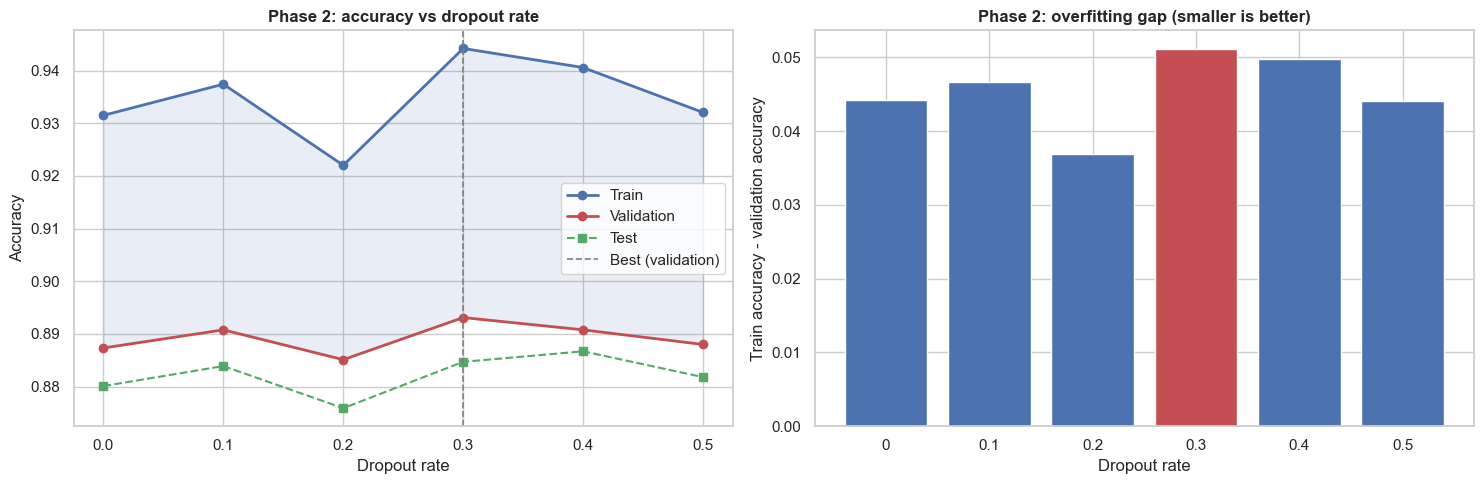

In [10]:
drop_df = pd.DataFrame(phase2_records).sort_values("dropout_mean")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(drop_df["dropout_mean"], drop_df["train_acc"], "o-", label="Train", color=PALETTE[0], linewidth=2)
axes[0].plot(drop_df["dropout_mean"], drop_df["val_acc"], "o-", label="Validation", color=PALETTE[3], linewidth=2)
axes[0].plot(drop_df["dropout_mean"], drop_df["test_acc"], "s--", label="Test", color=PALETTE[2], linewidth=1.5)
axes[0].fill_between(drop_df["dropout_mean"], drop_df["val_acc"], drop_df["train_acc"], alpha=0.12, color=PALETTE[0])
axes[0].axvline(best_dropout["dropout_mean"], color="gray", linestyle="--", linewidth=1.2, label="Best (validation)")
axes[0].set_xlabel("Dropout rate")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Phase 2: accuracy vs dropout rate", fontweight="bold")
axes[0].legend()

bar_colors = [PALETTE[3] if r == best_dropout["dropout_mean"] else PALETTE[0] for r in drop_df["dropout_mean"]]
axes[1].bar([f"{r:g}" for r in drop_df["dropout_mean"]], drop_df["gap"], color=bar_colors)
axes[1].set_xlabel("Dropout rate")
axes[1].set_ylabel("Train accuracy - validation accuracy")
axes[1].set_title("Phase 2: overfitting gap (smaller is better)", fontweight="bold")

fig.tight_layout()
save_figure(fig, "14_dropout_comparison.png")
plt.show()

## 6. Phase 3: Learning Rate

The learning rate controls the step size of Adam. **Too high** and training is unstable (the loss jumps around); **too low** and it converges slowly, so early stopping may end the run before the model has learned enough. Here the best architecture and best dropout rate from the earlier phases are used.

In [11]:
LEARNING_RATES = [1e-2, 3e-3, 1e-3, 3e-4, 1e-4]
best_units = best_dropout["config"]["hidden_units"]
best_rates = best_dropout["config"]["dropout_rates"]

phase3_records = [
    run_experiment(
        f"{best_dropout['layers']} | lr {lr:g}",
        best_units, best_rates, learning_rate=lr, phase="3-learning-rate",
    )
    for lr in LEARNING_RATES
]
show_table(phase3_records)

best_lr = pick_best(phase3_records)
print(f"\nBest learning rate by validation accuracy: {best_lr['learning_rate']:g} "
      f"-> val acc {best_lr['val_acc']:.4f}")

[14] 256 | lr 0.01                                  params=  204,298 epochs=18 val=0.8778 test=0.8710 time= 27.5s
[15] 256 | lr 0.003                                 params=  204,298 epochs=23 val=0.8864 test=0.8790 time= 35.3s
[cached] 256 | lr 0.001
[16] 256 | lr 0.0003                                params=  204,298 epochs=29 val=0.8897 test=0.8824 time= 45.2s
[17] 256 | lr 0.0001                                params=  204,298 epochs=58 val=0.8934 test=0.8875 time= 90.1s


name,layers,dropout,learning_rate,params,epochs_run,best_epoch,train_time_s,train_acc,val_acc,test_acc,gap
256 | lr 0.01,256,0.3,0.01,"204,298",18,10,28,0.9069,0.8778,0.8710,+0.0291
256 | lr 0.003,256,0.3,0.003,"204,298",23,15,35,0.9284,0.8864,0.8790,+0.0419
Shallow-Narrow,256,0.3,0.001,"204,298",30,22,48,0.9442,0.8931,0.8847,+0.0511
256 | lr 0.0003,256,0.3,0.0003,"204,298",29,21,45,0.9315,0.8897,0.8824,+0.0418
256 | lr 0.0001,256,0.3,0.0001,"204,298",58,50,90,0.9404,0.8934,0.8875,+0.0470



Best learning rate by validation accuracy: 0.0001 -> val acc 0.8934


Saved: reports/figures/15_learning_rate_comparison.png


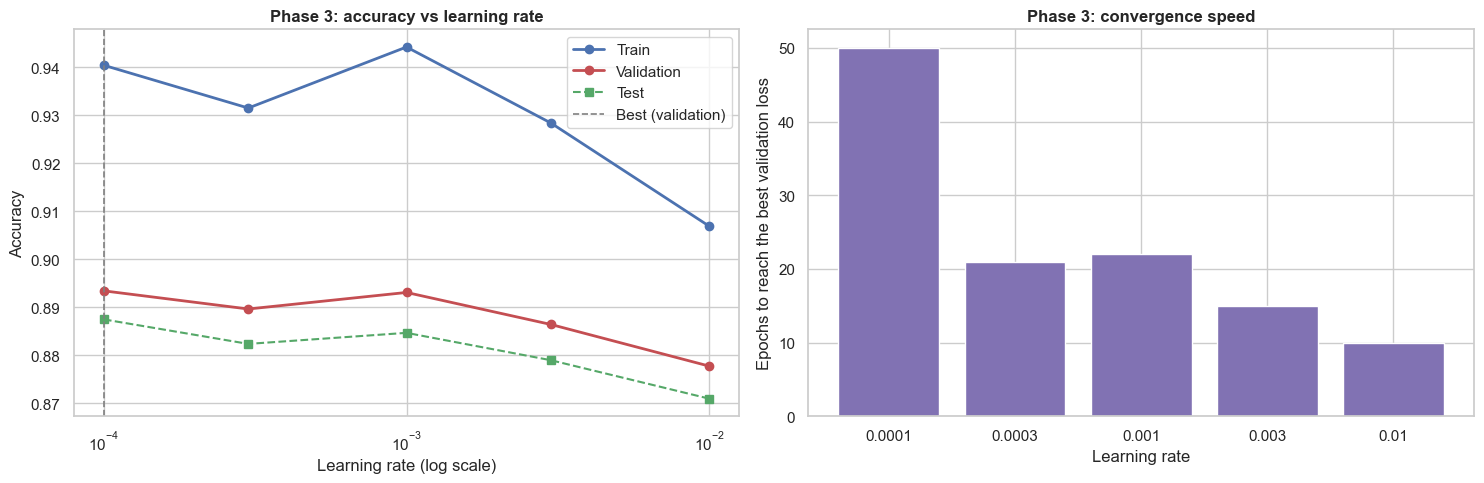

In [12]:
lr_df = pd.DataFrame(phase3_records).sort_values("learning_rate")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(lr_df["learning_rate"], lr_df["train_acc"], "o-", label="Train", color=PALETTE[0], linewidth=2)
axes[0].plot(lr_df["learning_rate"], lr_df["val_acc"], "o-", label="Validation", color=PALETTE[3], linewidth=2)
axes[0].plot(lr_df["learning_rate"], lr_df["test_acc"], "s--", label="Test", color=PALETTE[2], linewidth=1.5)
axes[0].axvline(best_lr["learning_rate"], color="gray", linestyle="--", linewidth=1.2, label="Best (validation)")
axes[0].set_xscale("log")
axes[0].set_xlabel("Learning rate (log scale)")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Phase 3: accuracy vs learning rate", fontweight="bold")
axes[0].legend()

axes[1].bar([f"{v:g}" for v in lr_df["learning_rate"]], lr_df["best_epoch"], color=PALETTE[4])
axes[1].set_xlabel("Learning rate")
axes[1].set_ylabel("Epochs to reach the best validation loss")
axes[1].set_title("Phase 3: convergence speed", fontweight="bold")

fig.tight_layout()
save_figure(fig, "15_learning_rate_comparison.png")
plt.show()

## 7. Phase 4: Robustness Across Random Seeds

Until now every configuration was trained once. Two runs of the *same* model with different random seeds can differ by 0.1 to 0.3 points, which is as large as many of the differences above. So before choosing, the **three best configurations** (by validation accuracy) and the **reference model** are each trained with several seeds. Only the seed changes (initial weights, dropout masks, batch order); the data split stays the same.

In [13]:
main_runs = pd.DataFrame(RESULTS)
main_runs = main_runs[main_runs["seed"] == SEED]
top3 = main_runs.sort_values(["val_acc", "val_loss"], ascending=[False, True]).head(3)

candidates = [row["config"] for _, row in top3.iterrows()]
if reference["config"] not in candidates:
    candidates.append(reference["config"])   # fair comparison against the starting point

print(f"Candidates ({len(candidates)}) x seeds {SEEDS}:")
for cfg in candidates:
    print("  -", config_label(cfg["hidden_units"], cfg["dropout_rates"], cfg["learning_rate"]))
print()

phase4_records = [
    run_experiment(
        "Robustness | " + config_label(cfg["hidden_units"], cfg["dropout_rates"], cfg["learning_rate"]),
        cfg["hidden_units"], cfg["dropout_rates"],
        learning_rate=cfg["learning_rate"], seed=seed, phase="4-robustness",
    )
    for cfg in candidates
    for seed in SEEDS
]

Candidates (4) x seeds (42, 43, 44):
  - 256 | dropout 0.3 | lr 0.0001
  - 256 | dropout 0.3 | lr 0.001
  - 512-256-128-64 | dropout 0.3 | lr 0.001
  - 512-256-128-64 | dropout 0.3-0.3-0.2-0.2 | lr 0.001

[cached] Robustness | 256 | dropout 0.3 | lr 0.0001
[18] Robustness | 256 | dropout 0.3 | lr 0.0001     params=  204,298 epochs=59 val=0.8923 test=0.8876 time= 89.1s
[19] Robustness | 256 | dropout 0.3 | lr 0.0001     params=  204,298 epochs=57 val=0.8898 test=0.8847 time= 92.9s
[cached] Robustness | 256 | dropout 0.3 | lr 0.001
[20] Robustness | 256 | dropout 0.3 | lr 0.001      params=  204,298 epochs=25 val=0.8880 test=0.8858 time= 41.5s
[21] Robustness | 256 | dropout 0.3 | lr 0.001      params=  204,298 epochs=19 val=0.8858 test=0.8799 time= 29.2s
[cached] Robustness | 512-256-128-64 | dropout 0.3 | lr 0.001
[22] Robustness | 512-256-128-64 | dropout 0.3 | lr 0.001 params=  577,930 epochs=25 val=0.8959 test=0.8882 time= 81.2s
[23] Robustness | 512-256-128-64 | dropout 0.3 | lr 0.

In [14]:
robust_df = pd.DataFrame(phase4_records)
final_df = (
    robust_df.groupby("config_label", sort=False)
    .agg(
        layers=("layers", "first"),
        dropout=("dropout", "first"),
        learning_rate=("learning_rate", "first"),
        params=("params", "first"),
        runs=("seed", "count"),
        val_acc_mean=("val_acc", "mean"),
        val_acc_std=("val_acc", "std"),
        test_acc_mean=("test_acc", "mean"),
        test_acc_std=("test_acc", "std"),
        gap_mean=("gap", "mean"),
        epochs_mean=("epochs_run", "mean"),
        time_mean_s=("train_time_s", "mean"),
    )
    .fillna(0.0)
)
reference_label = reference["config_label"]
final_df["is_reference"] = final_df.index == reference_label

display(
    final_df.sort_values("val_acc_mean", ascending=False).style.format({
        "learning_rate": "{:g}", "params": "{:,}",
        "val_acc_mean": "{:.4f}", "val_acc_std": "{:.4f}",
        "test_acc_mean": "{:.4f}", "test_acc_std": "{:.4f}",
        "gap_mean": "{:+.4f}", "epochs_mean": "{:.0f}", "time_mean_s": "{:.0f}",
    }).highlight_max(subset=["val_acc_mean"], color="#c6efce")
)

,layers,dropout,learning_rate,params,runs,val_acc_mean,val_acc_std,test_acc_mean,test_acc_std,gap_mean,epochs_mean,time_mean_s,is_reference
config_label,,,,,,,,,,,,,
512-256-128-64 | dropout 0.3-0.3-0.2-0.2 | lr 0.001,512-256-128-64,0.3-0.3-0.2-0.2,0.001,"577,930",3,0.8923,0.0024,0.8861,0.0037,+0.0411,26,87,True
256 | dropout 0.3 | lr 0.0001,256,0.3,0.0001,"204,298",3,0.8919,0.0019,0.8866,0.0016,+0.0483,58,91,False
512-256-128-64 | dropout 0.3 | lr 0.001,512-256-128-64,0.3,0.001,"577,930",3,0.8915,0.0044,0.8875,0.0009,+0.0430,27,89,False
256 | dropout 0.3 | lr 0.001,256,0.3,0.001,"204,298",3,0.8890,0.0038,0.8835,0.0031,+0.0446,25,40,False


Saved: reports/figures/16_seed_robustness.png


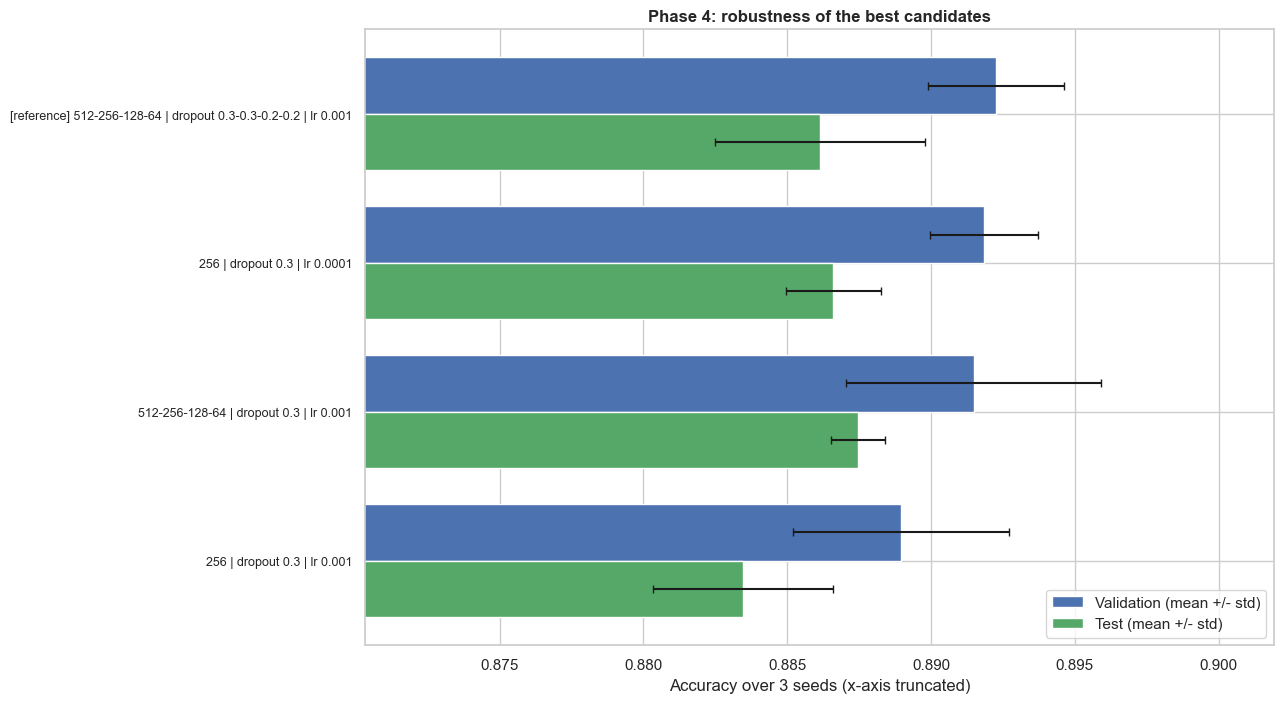

In [15]:
plot_df = final_df.sort_values("val_acc_mean")
fig, ax = plt.subplots(figsize=(13, 1.3 * len(plot_df) + 2))
y = np.arange(len(plot_df))
h = 0.38
ax.barh(y + h / 2, plot_df["val_acc_mean"], h, xerr=plot_df["val_acc_std"], capsize=3, label="Validation (mean +/- std)", color=PALETTE[0])
ax.barh(y - h / 2, plot_df["test_acc_mean"], h, xerr=plot_df["test_acc_std"], capsize=3, label="Test (mean +/- std)", color=PALETTE[2])
ax.set_yticks(y)
ax.set_yticklabels([("[reference] " if r else "") + label for label, r in zip(plot_df.index, plot_df["is_reference"])], fontsize=9)
low = min((plot_df["val_acc_mean"] - plot_df["val_acc_std"]).min(), (plot_df["test_acc_mean"] - plot_df["test_acc_std"]).min())
high = max((plot_df["val_acc_mean"] + plot_df["val_acc_std"]).max(), (plot_df["test_acc_mean"] + plot_df["test_acc_std"]).max())
ax.set_xlim(low - 0.01, high + 0.006)
ax.set_xlabel(f"Accuracy over {len(SEEDS)} seeds (x-axis truncated)")
ax.set_title("Phase 4: robustness of the best candidates", fontweight="bold")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "16_seed_robustness.png")
plt.show()

## 8. All Experiments

Every training run in one table, sorted by validation accuracy. The table is saved to `reports/experiment_results.csv`.

In [16]:
results_df = pd.DataFrame(RESULTS)
export_columns = [c for c in results_df.columns if c not in ("config", "config_label")]
results_df[export_columns].to_csv(REPORTS_DIR / "experiment_results.csv", index=False)
print(f"{len(results_df)} training runs saved to reports/experiment_results.csv\n")

show_table(
    results_df.sort_values(["val_acc", "val_loss"], ascending=[False, True]).to_dict("records"),
    columns=["phase"] + TABLE_COLUMNS + ["seed"],
)

25 training runs saved to reports/experiment_results.csv



phase,name,layers,dropout,learning_rate,params,epochs_run,best_epoch,train_time_s,train_acc,val_acc,test_acc,gap,seed
4-robustness,Robustness | 512-256-128-64 | dropout 0.3 | lr 0.001,512-256-128-64,0.3,0.001,"577,930",25,17,81,0.9330,0.8959,0.8882,+0.0372,43
4-robustness,Robustness | 512-256-128-64 | dropout 0.3-0.3-0.2-0.2 | lr 0.001,512-256-128-64,0.3-0.3-0.2-0.2,0.001,"577,930",28,20,91,0.9425,0.8950,0.8902,+0.0475,44
3-learning-rate,256 | lr 0.0001,256,0.3,0.0001,"204,298",58,50,90,0.9404,0.8934,0.8875,+0.0470,42
1-architecture,Shallow-Narrow,256,0.3,0.001,"204,298",30,22,48,0.9442,0.8931,0.8847,+0.0511,42
4-robustness,Robustness | 256 | dropout 0.3 | lr 0.0001,256,0.3,0.0001,"204,298",59,51,89,0.9406,0.8923,0.8876,+0.0483,43
1-architecture,Deep-4L,512-256-128-64,0.3,0.001,"577,930",29,21,93,0.9374,0.8916,0.8878,+0.0459,42
0-reference,Reference (project default),512-256-128-64,0.3-0.3-0.2-0.2,0.001,"577,930",29,21,103,0.9364,0.8910,0.8831,+0.0454,42
4-robustness,Robustness | 512-256-128-64 | dropout 0.3-0.3-0.2-0.2 | lr 0.001,512-256-128-64,0.3-0.3-0.2-0.2,0.001,"577,930",20,12,66,0.9212,0.8908,0.8851,+0.0304,43
2-dropout,Shallow-Narrow | dropout 0.4,256,0.4,0.001,"204,298",30,22,46,0.9406,0.8908,0.8867,+0.0498,42
2-dropout,Shallow-Narrow | dropout 0.1,256,0.1,0.001,"204,298",21,13,35,0.9374,0.8908,0.8839,+0.0467,42


Saved: reports/figures/17_accuracy_vs_parameters.png


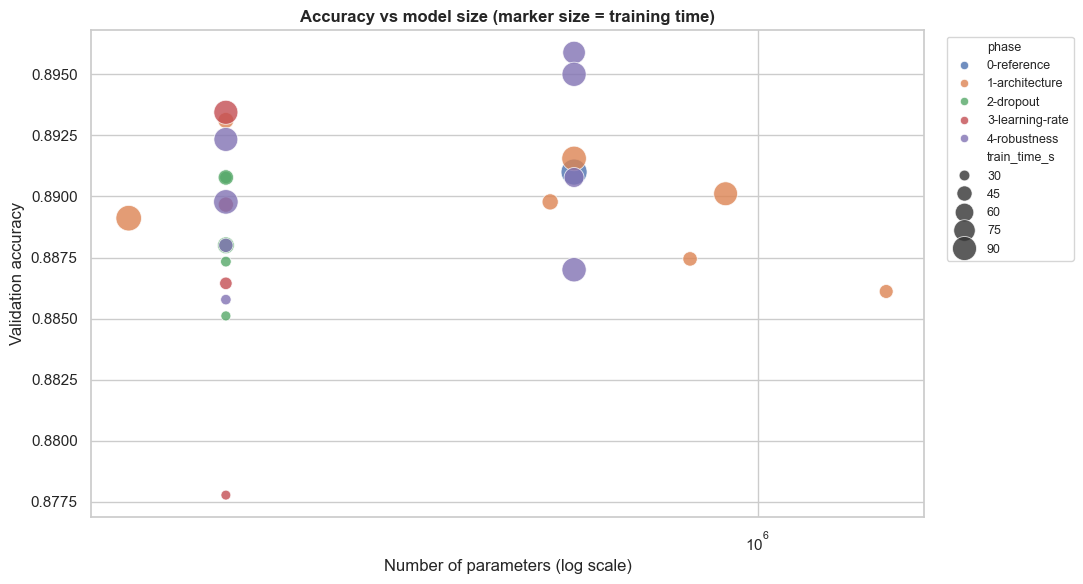

In [17]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(
    data=results_df, x="params", y="val_acc", hue="phase", size="train_time_s",
    sizes=(50, 350), alpha=0.8, palette="deep", ax=ax,
)
ax.set_xscale("log")
ax.set_xlabel("Number of parameters (log scale)")
ax.set_ylabel("Validation accuracy")
ax.set_title("Accuracy vs model size (marker size = training time)", fontweight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
fig.tight_layout()
save_figure(fig, "17_accuracy_vs_parameters.png")
plt.show()

## 9. Selecting the Best Model

**Selection rule (fixed before looking at the final numbers):**

1. Rank the configurations by **mean validation accuracy** over all seeds.
2. If several are within **0.05 points** of the top (a tie, given the seed-to-seed noise), choose the one with the **fewest parameters**: it is cheaper, faster, and less prone to overfitting.
3. Only then look at **test accuracy**, which serves as the final, untouched confirmation.

In [18]:
top_val = final_df["val_acc_mean"].max()
contenders = final_df[final_df["val_acc_mean"] >= top_val - TIE_MARGIN]
best_label = contenders.sort_values(["params", "val_acc_mean"], ascending=[True, False]).index[0]

best = final_df.loc[best_label]
ref = final_df.loc[reference_label]

print(f"Top mean validation accuracy : {top_val:.4f}")
print(f"Configurations in the tie    : {len(contenders)}")
print(f"Selected                     : {best_label}")

Top mean validation accuracy : 0.8923
Configurations in the tie    : 2
Selected                     : 256 | dropout 0.3 | lr 0.0001


Saved: reports/figures/18_selected_model_curves.png


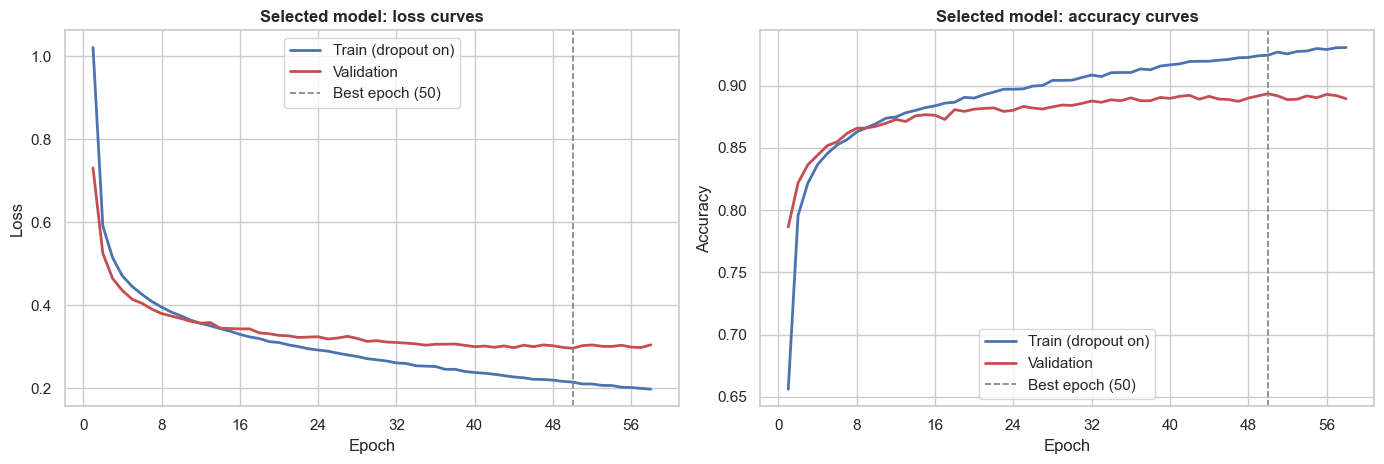

In [19]:
# Training curves of the selected model (main seed)
best_run = next(r for r in RESULTS if r["config_label"] == best_label and r["seed"] == SEED)
hist = HISTORIES[best_run["id"]]
epochs = np.arange(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(epochs, hist[metric], label="Train (dropout on)", color=PALETTE[0], linewidth=2)
    ax.plot(epochs, hist[f"val_{metric}"], label="Validation", color=PALETTE[3], linewidth=2)
    ax.axvline(best_run["best_epoch"], color="gray", linestyle="--", linewidth=1.2, label=f"Best epoch ({best_run['best_epoch']})")
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel(title)
    ax.set_title(f"Selected model: {title.lower()} curves", fontweight="bold")
    ax.legend()
fig.tight_layout()
save_figure(fig, "18_selected_model_curves.png")
plt.show()

### Justification

The text below is generated from the results above, so it always matches the numbers of the run you just executed.

In [20]:
d_test = best["test_acc_mean"] - ref["test_acc_mean"]
d_params = best["params"] - ref["params"]
noise = max(best["test_acc_std"], ref["test_acc_std"])
is_ref = best_label == reference_label

lines = [
    f"### Selected model: layers `{best['layers']}`, dropout `{best['dropout']}`, learning rate `{best['learning_rate']:g}`",
    "",
    f"- **Validation accuracy:** {best['val_acc_mean']:.2%} +/- {best['val_acc_std']:.2%} (mean +/- std over {int(best['runs'])} seeds). This is the number the choice was based on.",
    f"- **Test accuracy:** {best['test_acc_mean']:.2%} +/- {best['test_acc_std']:.2%}. This set was not used for any decision, so it is an unbiased estimate of real performance.",
    f"- **Size and cost:** {int(best['params']):,} parameters, about {best['epochs_mean']:.0f} epochs and {best['time_mean_s']:.0f} s of training.",
    f"- **Overfitting:** train accuracy is {best['gap_mean'] * 100:.2f} percentage points above validation accuracy.",
    "",
    "**What the experiments showed**",
    "",
    f"- *Architecture (phase 1):* `{best_arch['name']}` ({best_arch['layers']}) had the best validation accuracy of the {len(phase1_records)} architectures tried.",
    f"- *Dropout (phase 2):* a rate of `{best_dropout['dropout']}` worked best for that architecture.",
    f"- *Learning rate (phase 3):* `{best_lr['learning_rate']:g}` worked best.",
    "",
]

if is_ref:
    lines.append(
        "**Comparison with the reference:** the original project model turned out to be the best choice. "
        "Several alternatives were tried and none was clearly better, which confirms the original design."
    )
else:
    lines.append(
        f"**Comparison with the reference (project default):** mean test accuracy changed by "
        f"{d_test * 100:+.2f} percentage points and the parameter count by {d_params:+,} ({d_params / ref['params']:+.0%})."
    )
    if abs(d_test) <= noise:
        lines.append(
            f"The accuracy difference is within the seed-to-seed variation (+/- {noise * 100:.2f} points), so the two "
            "models perform comparably; the selected one is preferred because of its validation accuracy and its "
            "simpler/cheaper design."
        )
    elif d_test > 0:
        lines.append(
            f"The gain is larger than the seed-to-seed variation (+/- {noise * 100:.2f} points), so it is very likely "
            "a real improvement."
        )
    else:
        lines.append(
            f"The selected model scores lower on the test set than the reference by more than the seed-to-seed "
            f"variation (+/- {noise * 100:.2f} points). The choice was made on validation data, so its validation "
            "advantage did not carry over; consider keeping the reference or running more seeds."
        )

lines += [
    "",
    "**Limitations:** the search was greedy (one factor at a time), so interactions between factors may be missed; "
    "one data split was used; batch size, optimizer and weight decay were not explored. A fully connected network "
    "also has an inherent ceiling on image data, because it ignores the 2D structure of the pixels.",
]
display(Markdown("\n".join(lines)))

### Selected model: layers `256`, dropout `0.3`, learning rate `0.0001`

- **Validation accuracy:** 89.19% +/- 0.19% (mean +/- std over 3 seeds). This is the number the choice was based on.
- **Test accuracy:** 88.66% +/- 0.16%. This set was not used for any decision, so it is an unbiased estimate of real performance.
- **Size and cost:** 204,298 parameters, about 58 epochs and 91 s of training.
- **Overfitting:** train accuracy is 4.83 percentage points above validation accuracy.

**What the experiments showed**

- *Architecture (phase 1):* `Shallow-Narrow` (256) had the best validation accuracy of the 7 architectures tried.
- *Dropout (phase 2):* a rate of `0.3` worked best for that architecture.
- *Learning rate (phase 3):* `0.0001` worked best.

**Comparison with the reference (project default):** mean test accuracy changed by +0.05 percentage points and the parameter count by -373,632 (-65%).
The accuracy difference is within the seed-to-seed variation (+/- 0.37 points), so the two models perform comparably; the selected one is preferred because of its validation accuracy and its simpler/cheaper design.

**Limitations:** the search was greedy (one factor at a time), so interactions between factors may be missed; one data split was used; batch size, optimizer and weight decay were not explored. A fully connected network also has an inherent ceiling on image data, because it ignores the 2D structure of the pixels.

In [21]:
# Save the selected configuration so the training script can use it
best_config = {
    "hidden_units": list(best_run["config"]["hidden_units"]),
    "dropout_rates": list(best_run["config"]["dropout_rates"]),
    "learning_rate": best_run["config"]["learning_rate"],
    "batch_size": BATCH_SIZE,
    "early_stopping_patience": ES_PATIENCE,
    "n_parameters": int(best["params"]),
    "seeds": list(SEEDS),
    "val_accuracy_mean": round(float(best["val_acc_mean"]), 5),
    "val_accuracy_std": round(float(best["val_acc_std"]), 5),
    "test_accuracy_mean": round(float(best["test_acc_mean"]), 5),
    "test_accuracy_std": round(float(best["test_acc_std"]), 5),
    "quick_mode": QUICK_MODE,
}
path = REPORTS_DIR / "best_config.json"
path.write_text(json.dumps(best_config, indent=2))
print(f"Saved {path.relative_to(PROJECT_ROOT)}\n")
print(json.dumps(best_config, indent=2))

print("\nUse it in code:")
print(f"  build_model(hidden_units={tuple(best_config['hidden_units'])}, "
      f"dropout_rates={tuple(best_config['dropout_rates'])}, "
      f"learning_rate={best_config['learning_rate']:g})")

Saved reports/best_config.json

{
  "hidden_units": [
    256
  ],
  "dropout_rates": [
    0.3
  ],
  "learning_rate": 0.0001,
  "batch_size": 256,
  "early_stopping_patience": 8,
  "n_parameters": 204298,
  "seeds": [
    42,
    43,
    44
  ],
  "val_accuracy_mean": 0.89185,
  "val_accuracy_std": 0.00188,
  "test_accuracy_mean": 0.8866,
  "test_accuracy_std": 0.00165,
  "quick_mode": false
}

Use it in code:
  build_model(hidden_units=(256,), dropout_rates=(0.3,), learning_rate=0.0001)


## 10. Summary and Next Steps

- A systematic search over **depth, width, dropout and learning rate** was run with early stopping, and the winner was confirmed across several random seeds.
- Selection used **validation data only**; test accuracy is reported as the final confirmation.
- All numbers are saved in `reports/experiment_results.csv`, the chosen settings in `reports/best_config.json`, and the figures in `reports/figures/13_*.png` to `18_*.png`.

**Next steps**

1. Retrain the final model with `src/train.py` using the settings from `best_config.json`, then re-run `src/evaluate.py` for the confusion matrix and per-class report.
2. Possible extensions: L2 weight decay, learning-rate schedules (`ReduceLROnPlateau` is already available in `train.py`), batch-size and optimizer search, and automated search with Keras Tuner.